# MIST_Maps Example Cases (`ComboTile`, `JTile`, `LunarTile`, `TerrainData`)

This notebook demonstrates the **MIST_Maps** terrain analysis workflow across Earth and Lunar Digital Surface/Elevation Models (DSMs/DEMs):

1. **Earth 5×5 Mosaic (`ComboTile`)**: Axel Heiberg Island, Nunavut (`Arctic_Data/`, MIST `mars2024_spot1` site) — mosaicking tiles with missing coastal/ocean coverage, nodata masking, elevation & slope mapping with observer markers, windowed ENU horizon profiling, polar sky-view plotting, sky-view fraction metrics, and CSV export.
2. **Single-Tile Earth Analysis & HDF5 Export (`JTile` + `TerrainData`)**: Coordinate transforms, tabular terrain export, and compressed HDF5 serialization round-trip.
3. **Moon Crater Horizon (`LunarTile`)**: Copernicus Crater (`lunar_9.62_-20.08.tif`) — lunar ellipsoid ENU projection, raw-pixel vs. binned horizon profile, sky-view summary, and curved-Moon vs. flat-Moon comparison.
4. **Lunar Crater vs. Equatorial Mare Comparison (`LunarTile`)**: Tycho Crater (`lunar_-43.37_-11.36.tif`) vs. Equatorial Mare (`lunar_0.0_0.0.tif`).

In [1]:
import os
import tempfile
import numpy as np
import matplotlib.pyplot as plt

from ComboTile import ComboTile, JTile, LunarTile
from TerrainData import TerrainData

## Example 1: Earth 5×5 Mosaic — Axel Heiberg Island (`Arctic_Data`)

The `Arctic_Data/` directory contains 21 of the 25 ALOS AW3D30 1-degree tiles centered around `79 N / 91 W` (four northern ocean tiles are absent and automatically filled with `nodata = -9999`, which `ComboTile` masks before plotting, differentiating, and computing horizon angles).

Observer site: MIST `mars2024_spot1` at `lat0 = 79.41861°`, `lon0 = -90.74778°`.

In [2]:
arctic = ComboTile("79 N / 91 W", root_dir="Arctic_Data")

obs_lon, obs_lat = -90.74778, 79.41861
min_lon, max_lon, min_lat, max_lat = arctic.tile_bounds()
print(f"Mosaic bounds: lon [{min_lon:.2f}, {max_lon:.2f}], lat [{min_lat:.2f}, {max_lat:.2f}]")

21 file(s) successfully opened.
4 file(s) missing or failed to open:
  - Arctic_Data/ALPSMLC30_N077W093_DSM.tif: Arctic_Data/ALPSMLC30_N077W093_DSM.tif: No such file or directory
  - Arctic_Data/ALPSMLC30_N080W089_DSM.tif: Arctic_Data/ALPSMLC30_N080W089_DSM.tif: No such file or directory
  - Arctic_Data/ALPSMLC30_N080W093_DSM.tif: Arctic_Data/ALPSMLC30_N080W093_DSM.tif: No such file or directory
  - Arctic_Data/ALPSMLC30_N081W093_DSM.tif: Arctic_Data/ALPSMLC30_N081W093_DSM.tif: No such file or directory


CRS: EPSG:4326, Shape: (18000, 6000), Center (lon, lat): (-90.5, 79.5)
Mosaic bounds: lon [-93.00, -88.00], lat [77.00, 82.00]


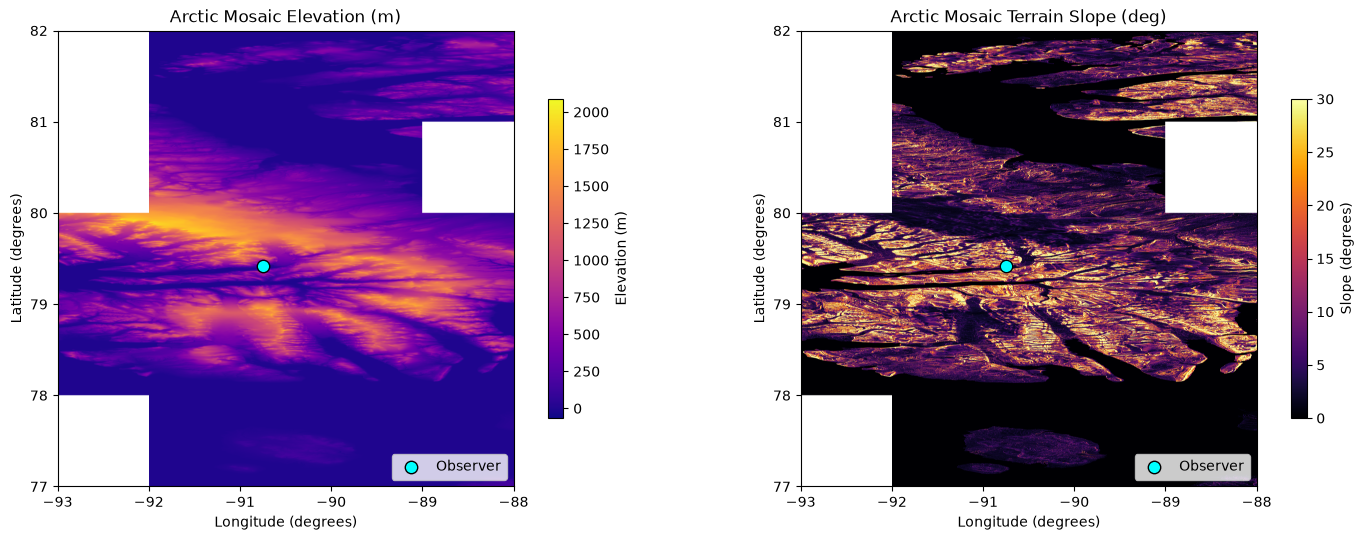

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

arctic.plot_map(ax=ax1, observer=(obs_lon, obs_lat))
ax1.set_title("Arctic Mosaic Elevation (m)")
ax1.legend(loc="lower right")

arctic.plot_slope(want_log=False, ax=ax2, vmax=30.0, observer=(obs_lon, obs_lat))
ax2.set_title("Arctic Mosaic Terrain Slope (deg)")
ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()

Horizon bins: 73 (0° to 360° step 5°)
Max horizon angle: 14.16° at azimuth 115° (r = 0.17 km, dz = 42.8 m)
Sky-view summary: {'sky_view_solid': 0.8519410993704511, 'sky_view_cos2': 0.9740571712188211, 'mean_horizon_deg': 8.530974184800927, 'max_horizon_deg': 14.163141919816185, 'min_horizon_deg': 0.9611340084849677}


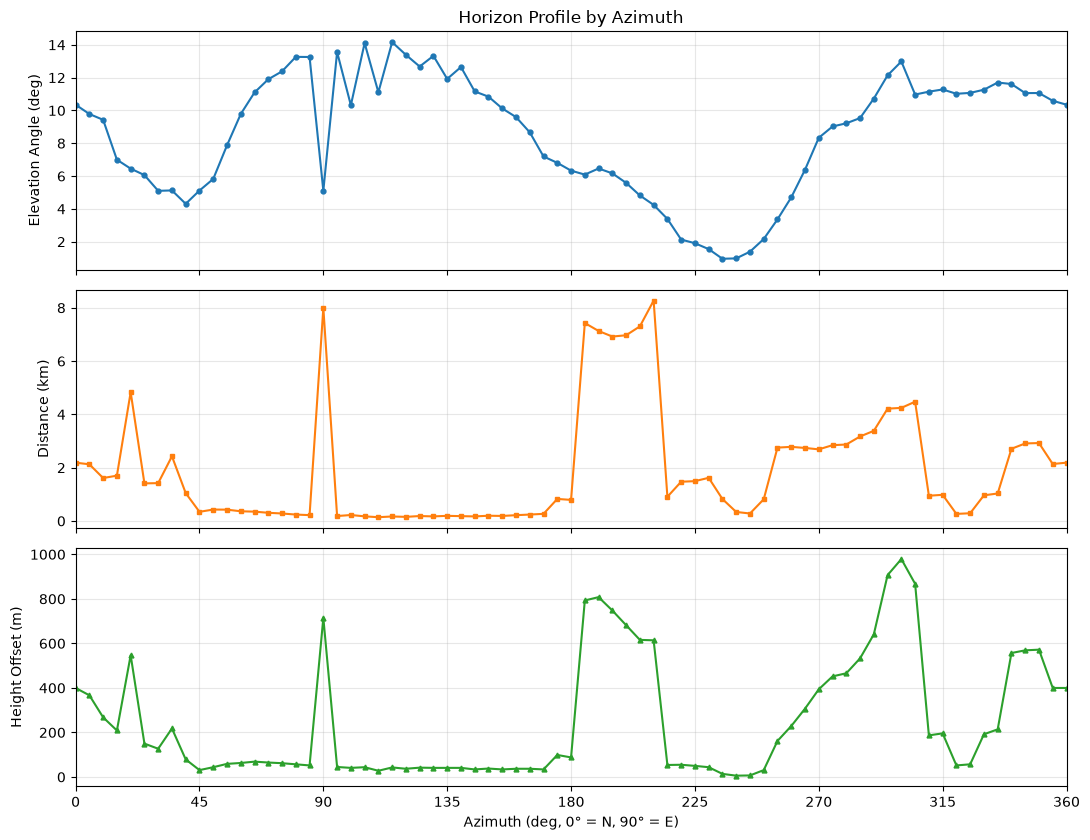

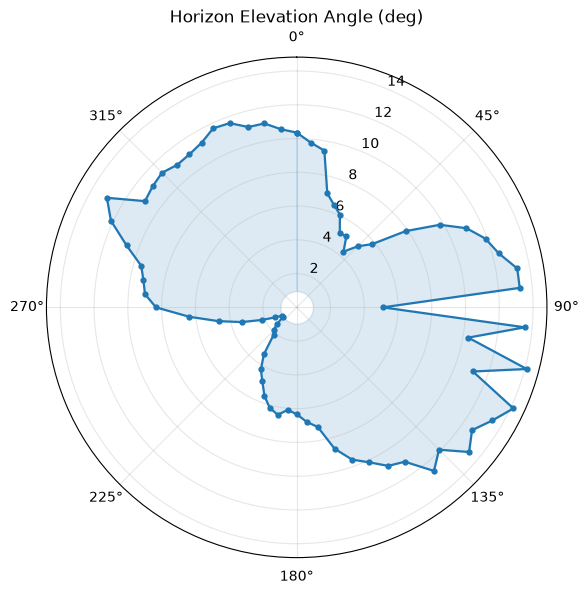

Wrote 7035 bytes to horizon CSV.


In [4]:
az_centers, max_elev, max_r, max_z, max_coords = arctic.max_elev_enu(
    bin_width=5.0,
    radius_max_meters=20_000.0,
    radius0_meters=200.0,
    lon0=obs_lon,
    lat0=obs_lat,
)

svf = ComboTile.sky_view_fraction(az_centers, max_elev)
peak_idx = int(np.nanargmax(max_elev))
print(f"Horizon bins: {len(az_centers)} (0° to 360° step 5°)")
print(f"Max horizon angle: {max_elev[peak_idx]:.2f}° at azimuth {az_centers[peak_idx]:.0f}° "
      f"(r = {max_r[peak_idx]/1e3:.2f} km, dz = {max_z[peak_idx]:.1f} m)")
print(f"Sky-view summary: {svf}")

arctic.plot_horizon(az_centers, max_elev, max_r, max_z)
plt.show()

arctic.plot_horizon(az_centers, max_elev, polar=True)
plt.show()

with tempfile.TemporaryDirectory() as tmpdir:
    csv_path = os.path.join(tmpdir, "arctic_horizon.csv")
    ComboTile.save_horizon_csv(csv_path, az_centers, max_elev, max_r, max_z, max_coords)
    print(f"Wrote {os.path.getsize(csv_path)} bytes to horizon CSV.")

## Example 2: Single-Tile Earth Analysis & HDF5 Export (`JTile` + `TerrainData`)

`JTile` loads a single 1-degree ALOS tile without mosaicking. Below we inspect coordinate conversions (`lonlat_to_xy`, `xy_to_lonlat`), tabular gradient output (`map_table`), and lossless HDF5 persistence via `save_data` and `TerrainData.load_terrain_data`.

In [5]:
single_tile = JTile("079 N / 091 W", root_dir="Arctic_Data")
col, row = single_tile.lonlat_to_xy(obs_lon, obs_lat)
lon_rt, lat_rt = single_tile.xy_to_lonlat(col, row)
px_info = single_tile.get_elevation(row, col)

print(f"Tile shape: {single_tile.shape}, CRS: {single_tile.crs}")
print(f"Observer pixel (col, row): ({col}, {row}) -> round-trip ({lon_rt:.5f}°, {lat_rt:.5f}°)")
print(f"get_elevation(row, col) [lat, lon, elev_m]: {px_info}")

table = single_tile.map_table(want_grad=True)
print(f"map_table(want_grad=True) shape: {table.shape}, max slope: {np.nanmax(table[:, 6]):.2f}°")

with tempfile.TemporaryDirectory() as tmpdir:
    h5_path = os.path.join(tmpdir, "arctic_sample.h5")
    single_tile.save_data(h5_path, compute_gradients=True)
    loaded = TerrainData.load_terrain_data(h5_path)
    print(f"HDF5 round-trip shape: {loaded.shape}, max abs diff: "
          f"{np.max(np.abs(loaded.get_elevation() - single_tile.elevations)):.6f} m")

Tile shape: (3600, 1200), CRS: EPSG:4326
Observer pixel (col, row): (302, 2093) -> round-trip (-90.74792°, 79.41847°)
get_elevation(row, col) [lat, lon, elev_m]: [ 79.41847222 -90.74791667 174.        ]


map_table(want_grad=True) shape: (4320000, 7), max slope: 76.98°


HDF5 round-trip shape: (3600, 1200), max abs diff: 0.000000 m


## Example 3: Lunar Crater Horizon (`LunarTile`) — Copernicus Crater

`LunarTile` loads USGS LRO WAC GLD100 GeoTIFF clips (100 m/pixel), uses the IAU Moon reference ellipsoid in `pymap3d.geodetic2enu`, and computes 3-D ENU horizon angles over 100 km baselines.

Notice the **curvature effect**: because `geodetic2enu` transforms terrain points into the observer's local tangent plane, distant lunar features at $r = 100\,\text{km}$ sit roughly $r^2 / (2 R_{\text{moon}}) \approx 2.88\,\text{km}$ ($\approx 1.65^\circ$) lower than a flat-Moon height difference would suggest.

Loaded lunar_9.62_-20.08.tif | CRS: GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",1737400,0]],PRIMEM["Reference meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]]
  Center: (9.6200°, -20.0800°), Shape: (1516, 1516)
  Bounds: Lat [7.1200, 12.1200], Lon [-22.5800, -17.5800]
  Resolution: ~0.003298°/px


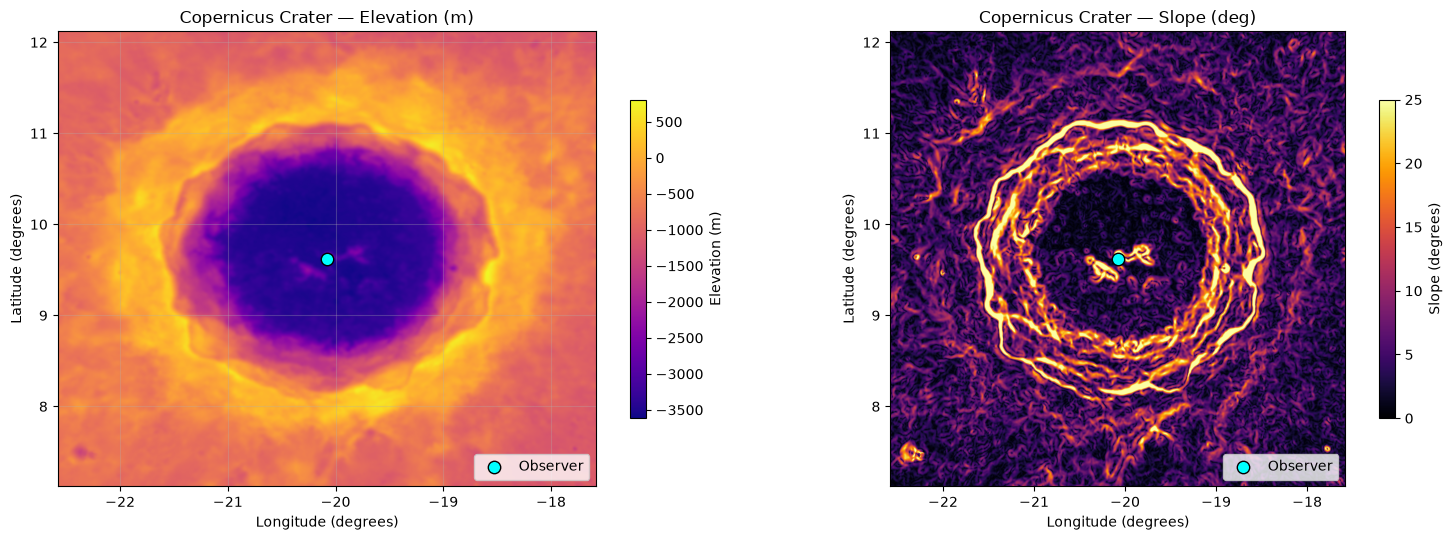

In [6]:
copernicus = LunarTile("lunar_9.62_-20.08.tif", root_dir="Lunar_Test_Data")
cop_lon0, cop_lat0 = -20.08, 9.62

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
copernicus.plot_map(ax=ax1, observer=(cop_lon0, cop_lat0))
ax1.set_title("Copernicus Crater — Elevation (m)")
ax1.legend(loc="lower right")

copernicus.plot_slope(want_log=False, ax=ax2, vmax=25.0, observer=(cop_lon0, cop_lat0))
ax2.set_title("Copernicus Crater — Slope (deg)")
ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()

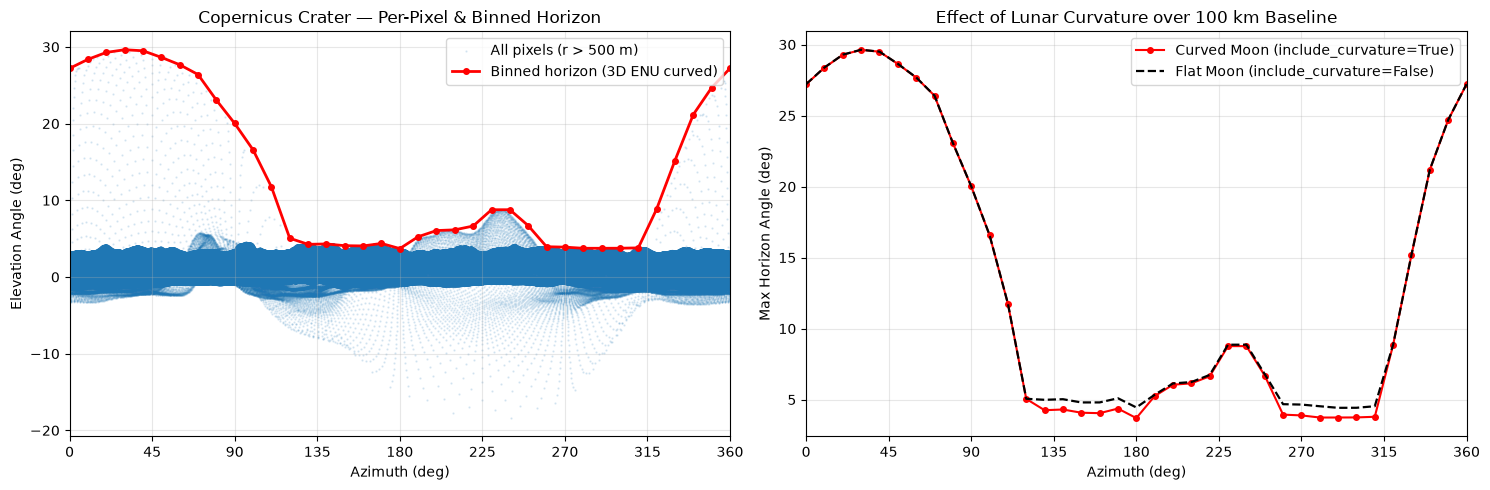

Max horizon difference (flat - curved): 0.79°
Copernicus sky-view: {'sky_view_solid': 0.778514325261352, 'sky_view_cos2': 0.9232108693984704, 'mean_horizon_deg': 13.026985291364717, 'max_horizon_deg': 29.627608834795986, 'min_horizon_deg': 3.7005758512271245}


In [7]:
el_deg, az_deg, az_c, max_curved, max_r_c, max_z_c, _ = copernicus.max_elev_enu(
    bin_width=10.0,
    radius_max_meters=100_000.0,
    lon0=cop_lon0,
    lat0=cop_lat0,
    include_curvature=True,
)
_, _, _, max_flat, _, _, _ = copernicus.max_elev_enu(
    bin_width=10.0,
    radius_max_meters=100_000.0,
    lon0=cop_lon0,
    lat0=cop_lat0,
    include_curvature=False,
)

az_deg_wrapped = (az_deg + 360.0) % 360.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.scatter(az_deg_wrapped, el_deg, s=0.4, alpha=0.15, color="tab:blue", label="All pixels (r > 500 m)")
ax1.plot(az_c, max_curved, "r-o", markersize=4, linewidth=2, label="Binned horizon (3D ENU curved)")
ax1.set_title("Copernicus Crater — Per-Pixel & Binned Horizon")
ax1.set_xlabel("Azimuth (deg)")
ax1.set_ylabel("Elevation Angle (deg)")
ax1.set_xlim(0, 360)
ax1.set_xticks(np.arange(0, 361, 45))
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper right")

ax2.plot(az_c, max_curved, "r-o", markersize=4, label="Curved Moon (include_curvature=True)")
ax2.plot(az_c, max_flat, "k--", linewidth=1.6, label="Flat Moon (include_curvature=False)")
ax2.set_title("Effect of Lunar Curvature over 100 km Baseline")
ax2.set_xlabel("Azimuth (deg)")
ax2.set_ylabel("Max Horizon Angle (deg)")
ax2.set_xlim(0, 360)
ax2.set_xticks(np.arange(0, 361, 45))
ax2.grid(True, alpha=0.3)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

print(f"Max horizon difference (flat - curved): {np.max(max_flat - max_curved):.2f}°")
print("Copernicus sky-view:", LunarTile.sky_view_fraction(az_c, max_curved))

## Example 4: Tycho Crater vs. Equatorial Mare (`LunarTile`)

Comparing a high-relief crater interior (Tycho, `-43.37°N, -11.36°E`) with a flat equatorial mare plain (`0.0°N, 0.0°E`). Because the mare has minimal relief, lunar curvature pushes most distant terrain below the observer's local tangent plane (`max_elev <= 0°`).

Loaded lunar_-43.37_-11.36.tif | CRS: GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",1737400,0]],PRIMEM["Reference meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]]
  Center: (-43.3700°, -11.3600°), Shape: (1516, 1516)
  Bounds: Lat [-45.8700, -40.8700], Lon [-13.8600, -8.8600]
  Resolution: ~0.003298°/px
Loaded lunar_0.0_0.0.tif | CRS: GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",1737400,0]],PRIMEM["Reference meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]]
  Center: (0.0000°, 0.0000°), Shape: (1516, 1516)
  Bounds: Lat [-2.5000, 2.5000], Lon [-2.5000, 2.5000]
  Resolution: ~0.003298°/px


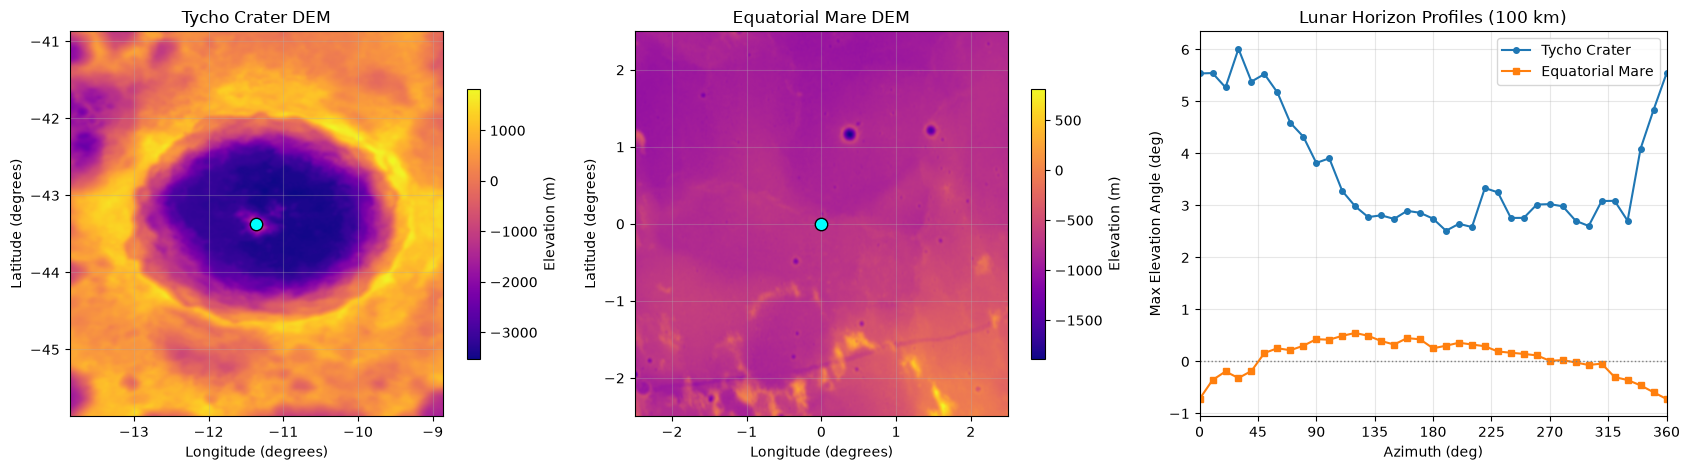

Tycho sky-view: {'sky_view_solid': 0.9369344558989354, 'sky_view_cos2': 0.9956683276160186, 'mean_horizon_deg': 3.616491051729231, 'max_horizon_deg': 6.012639097407993, 'min_horizon_deg': 2.5138805194583376}
Mare sky-view:  {'sky_view_solid': 0.9965540582306264, 'sky_view_cos2': 0.9999780211717842, 'mean_horizon_deg': 0.0971857003518963, 'max_horizon_deg': 0.5482586759021655, 'min_horizon_deg': -0.7216655654295524}


In [8]:
tycho = LunarTile("lunar_-43.37_-11.36.tif", root_dir="Lunar_Test_Data")
mare = LunarTile("lunar_0.0_0.0.tif", root_dir="Lunar_Test_Data")

_, _, az_tycho, max_tycho, _, _, _ = tycho.max_elev_enu(
    bin_width=10.0, radius_max_meters=100_000.0, lon0=-11.36, lat0=-43.37
)
_, _, az_mare, max_mare, _, _, _ = mare.max_elev_enu(
    bin_width=10.0, radius_max_meters=100_000.0, lon0=0.0, lat0=0.0
)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
tycho.plot_map(ax=axes[0], observer=(-11.36, -43.37))
axes[0].set_title("Tycho Crater DEM")

mare.plot_map(ax=axes[1], observer=(0.0, 0.0))
axes[1].set_title("Equatorial Mare DEM")

axes[2].plot(az_tycho, max_tycho, "o-", markersize=4, label="Tycho Crater")
axes[2].plot(az_mare, max_mare, "s-", markersize=4, label="Equatorial Mare")
axes[2].axhline(0.0, color="gray", linestyle=":", linewidth=1)
axes[2].set_title("Lunar Horizon Profiles (100 km)")
axes[2].set_xlabel("Azimuth (deg)")
axes[2].set_ylabel("Max Elevation Angle (deg)")
axes[2].set_xlim(0, 360)
axes[2].set_xticks(np.arange(0, 361, 45))
axes[2].grid(True, alpha=0.3)
axes[2].legend(loc="upper right")

plt.tight_layout()
plt.show()

print("Tycho sky-view:", LunarTile.sky_view_fraction(az_tycho, max_tycho))
print("Mare sky-view: ", LunarTile.sky_view_fraction(az_mare, max_mare))